In [1]:
from model.Model import model_MSG
from model.Plotter import plotter_MSG
from model.coders_linkage import CODERS_pull
from pstats import SortKey, Stats

import os
import sys

# Autoreload modules when changes are applied to them
%load_ext autoreload 
%autoreload all


In [2]:

# Autoreload modules when changiges are applied to them
%load_ext autoreload 
%autoreload all

%reload_ext autoreload
# Set-up
# Sys and OS Operations
os.chdir("../../")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
msg = model_MSG(scenario_name='baseline')
platform, msg_scenario, msg_folder = msg.setup_scenario()

2024-12-01 20:50:38,101  INFO at.ac.iiasa.ixmp.Platform:165 - Welcome to the IX modeling platform!
2024-12-01 20:50:38,107  INFO at.ac.iiasa.ixmp.Platform:166 -  connected to database 'jdbc:hsqldb:file:/Users/muhammadawais/.local/share/ixmp/localdb/default' (user: ixmp)...
Config file read successfully!
####################################################################################################
Config file 'model/scenarios/baseline/config.toml' passed format verification!
####################################################################################################
####################################################################################################
 Added OBPS policy to the model!
####################################################################################################

		Model creation time: 5 Min and 56 Sec 		
Solving the model...

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/01

2024-12-02 16:12:15,750 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-12-02 16:12:15,755 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!



				Solving process time: 2 Min and 41 Sec				
processing Table: Resource|Extraction
processing Table: Resource|Cumulative Extraction
processing Table: Primary Energy
processing Table: Primary Energy (substitution method)
processing Table: Final Energy
processing Table: Secondary Energy|Electricity
processing Table: Secondary Energy|Heat
processing Table: Secondary Energy
processing Table: Secondary Energy|Gases
processing Table: Secondary Energy|Solids
processing Table: Emissions|CO2
processing Table: Carbon Sequestration
processing Table: Emissions|BC
processing Table: Emissions|OC
processing Table: Emissions|CO
processing Table: Emissions|N2O
processing Table: Emissions|CH4
processing Table: Emissions|NH3
processing Table: Emissions|Sulfur
processing Table: Emissions|NOx
processing Table: Emissions|VOC
processing Table: Emissions|HFC
HFC125
No objects to concatenate
processing Table: Emissions
processing Table: Emissions
processing Table: Agricultural Demand
module 'message_ix_mode

In [5]:
msg_scenario.remove_solution()

In [37]:
msg_scenario.check_out()

In [8]:
df = msg_scenario.par('growth_activity_lo')
# Apply condition for 'gas_extr_1', 'gas_extr_2', ..., 'gas_extr_6'
df.loc[df['technology'].str.contains('gas_exp'), 'value'] = -0.05


In [38]:
# Retrieve the DataFrame
df = msg_scenario.par('growth_activity_lo')

# Define the conditions
condition_1 = df['technology'].str.contains('gas_exp', na=False)
condition_2 = df['node_loc'].isin(['Ontario', 'Manitoba'])
condition_3 = df['year_act'] == 2025

# Apply the conditions to modify the 'value' column
df.loc[condition_1 & condition_2 & condition_3, 'value'] = -0.4


In [39]:
msg_scenario.add_par('growth_activity_lo', df)

In [ ]:
msgopt = msg_scenario.clone(msg_scenario.model, 'netzero_opt',
                     keep_solution=False)

In [5]:
import pandas as pd

In [7]:
msgopt = msg_scenario.clone(msg_scenario.model, 'netzero_opt',
                     keep_solution=False)

df = pd.read_excel(
    '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero_opt/Inv_cost_high_LR.xlsx')

msgopt.check_out()
msgopt.add_par('inv_cost', df)
msgopt.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgopt.model + '__' + msgopt.scenario + '__v' + str(msgopt.version)
msgopt.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 11/30/24 11:44:55 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_opt__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero_opt__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero_opt__v1.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

ModelError: GAMS returned 0 but indicated:
    LP status (5): optimal with unscaled infeasibilities
and JDBCBackend could not read the solution.

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_opt__v1.gdx

In [11]:
caseName = msgopt.model + '__' + msgopt.scenario + '__v' + str(msgopt.version)

In [12]:
msgopt.to_excel(f'{caseName}.xlsx')

In [8]:
msgpes = msg_scenario.clone(msg_scenario.model, 'netzero_pes',
                     keep_solution=False)

df = pd.read_excel(
    '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero_pes/Inv_cost_low_LR.xlsx')

msgpes.check_out()
msgpes.add_par('inv_cost', df)
msgpes.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgpes.model + '__' + msgpes.scenario + '__v' + str(msgpes.version)
msgpes.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 11/30/24 11:47:15 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_pes__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero_pes__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero_pes__v1.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

2024-11-30 11:49:33,927 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-11-30 11:49:33,931 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [10]:
msgpes.to_excel(f'{caseName}.xlsx')


In [5]:
msg_scenario.check_out()

In [14]:
df = msg_scenario.par('bound_activity_up',filters = {'technology':'solar_pv_ppl'})

In [16]:
msg_scenario.remove_par('bound_activity_up', df)

In [15]:
import pandas as pd
# Manually entered data (example)
data = {
    'node': ['Canada'],
    'type_emission': ['TCE'],
    'type_tec':['all'],
    'type_year':[2020],
    'value': [1.81E+09],
    'unit':'-'
}

# Convert data to a DataFrame
df = pd.DataFrame(data)


In [16]:
df

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2020,1.810000e+09,-


In [17]:
msg_scenario.add_par('bound_emission',df)

In [13]:
msg_scenario.add_par('emission_scaling',df)

In [12]:
msg_scenario.check_out()

In [9]:
import pandas as pd

In [10]:
df = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/baseline/emission_scaling.csv')

In [6]:
msg_scenario.remove_solution()

## Adjust Hydro, wind and solar bounds

In [ ]:
df = msg_scenario.par('bound_activity_lo')
df = df[df['technology'].str.contains('hydro')]

import pandas as pd
# Generate additional years (2030 to 2060 with a 5-year step)
years = range(2030, 2061, 5)

# Replicate the data for each year
replicated_data = []
for year in years:
    new_data = df.copy()
    new_data["year_act"] = year
    replicated_data.append(new_data)

# Combine all dataframes
df_extended = pd.concat([df] + replicated_data, ignore_index=True)

msg_scenario.add_par('bound_activity_lo', df_extended)
df_extended['value'] = df_extended['value'] * 1.1
msg_scenario.add_par('bound_activity_up', df_extended)


In [20]:
msg_scenario

In [25]:
import pandas as pd

In [186]:
data = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/data/CODERS_data/CER_nuclear.csv')

# Define the region renaming map and desired region format
region_rename_map = {
    'NEWFOUNDLAND AND LABRADOR': 'NewfoundlandandLabrador',
    'BRITISH COLUMBIA': 'BritishColumbia',
    'PRINCE EDWARD ISLAND': 'PrinceEdwardIsland',
    'NORTHWEST TERRITORIES': 'NorthwestTerritories',
    'YUKON': 'Yukon',
    'NOVA SCOTIA': 'NovaScotia',
    'NEW BRUNSWICK': 'NewBrunswick',
    'ONTARIO': 'Ontario',
    'QUEBEC': 'Quebec',
    'ALBERTA': 'Alberta',
    'SASKATCHEWAN': 'Saskatchewan',
    'MANITOBA': 'Manitoba',
    'NUNAVUT': 'Nunavut'
}

# Rename regions
data['region'] = data['region'].str.upper().map(region_rename_map)

# Filter for 5-year timesteps starting at 2020
# Replace 2023 with 2020 and exclude existing 2020 entries
data = data[(data['year'] % 5 == 0) | (data['year'] == 2023)]
data.loc[data['year'] == 2023, 'year'] = 2020

# Exclude existing 2020 entries that weren't modified
data = data.drop_duplicates(subset=['region', 'year', 'scenario', 'source'], keep='last')

data.rename(columns={'source': 'technology', 'region': 'node_loc', 'year': 'year_act'}, inplace=True)
data.drop(columns = ['scenario','dataset'], inplace=True)
data['technology'] = 'nuc_lc'
data['value'] = data['value'] / (8.76*3.6)
data['unit'] = 'GWa/a'
data['mode'] ='M1'
data['time'] = 'year'

# Step 1: Filter the dataset for the year 2050 to get the reference values
data_2050 = data[data['year_act'] == 2050]

# Step 2: Create new rows for 2055 and 2060 using the 2050 values
data_extended = pd.concat([
    data,
    data_2050.assign(year_act=2055),
    data_2050.assign(year_act=2060)
])

# Step 3: Sort the extended dataset by `node_loc` and `year_act` for clarity
data_extended = data_extended.sort_values(by=['node_loc', 'year_act']).reset_index(drop=True)

data_extended

,node_loc,technology,year_act,value,unit,mode,time
0,Alberta,nuc_lc,2005,0.00000,GWa/a,M1,year
1,Alberta,nuc_lc,2010,0.00000,GWa/a,M1,year
2,Alberta,nuc_lc,2015,0.00000,GWa/a,M1,year
3,Alberta,nuc_lc,2020,0.00000,GWa/a,M1,year
4,Alberta,nuc_lc,2025,0.00000,GWa/a,M1,year
...,...,...,...,...,...,...,...
106,Saskatchewan,nuc_lc,2055,0.74353,GWa/a,M1,year
107,Saskatchewan,nuc_lc,2060,0.74353,GWa/a,M1,year
108,Yukon,nuc_lc,2005,0.00000,GWa/a,M1,year
109,Yukon,nuc_lc,2010,0.00000,GWa/a,M1,year


In [187]:
data_extended

,node_loc,technology,year_act,value,unit,mode,time
0,Alberta,nuc_lc,2005,0.00000,GWa/a,M1,year
1,Alberta,nuc_lc,2010,0.00000,GWa/a,M1,year
2,Alberta,nuc_lc,2015,0.00000,GWa/a,M1,year
3,Alberta,nuc_lc,2020,0.00000,GWa/a,M1,year
4,Alberta,nuc_lc,2025,0.00000,GWa/a,M1,year
...,...,...,...,...,...,...,...
106,Saskatchewan,nuc_lc,2055,0.74353,GWa/a,M1,year
107,Saskatchewan,nuc_lc,2060,0.74353,GWa/a,M1,year
108,Yukon,nuc_lc,2005,0.00000,GWa/a,M1,year
109,Yukon,nuc_lc,2010,0.00000,GWa/a,M1,year


In [180]:
msg_scenario.remove_solution()

In [181]:
msg_scenario.check_out()

In [182]:
# msg_scenario.check_out()
data_hist= data[data['year_act'] <= 2020]
msg_scenario.add_par('historical_activity', data_hist)
data_future = data[data['year_act'] >= 2020]
msg_scenario.add_par('bound_activity_lo', data_extended)

In [35]:
msg_scenario.par('bound_activity_lo', filters = {'technology':'wind_ppl'})

,node_loc,technology,year_act,mode,time,value,unit
0,NewfoundlandandLabrador,wind_ppl,2030,M1,year,0.022203,GWa/a
1,NewfoundlandandLabrador,wind_ppl,2040,M1,year,0.022203,GWa/a
2,NewfoundlandandLabrador,wind_ppl,2050,M1,year,0.033960,GWa/a
3,NewfoundlandandLabrador,wind_ppl,2025,M1,year,0.022203,GWa/a
4,NewfoundlandandLabrador,wind_ppl,2035,M1,year,0.022203,GWa/a
...,...,...,...,...,...,...,...
86,NorthwestTerritories,wind_ppl,2040,M1,year,0.006780,GWa/a
87,NorthwestTerritories,wind_ppl,2050,M1,year,0.009866,GWa/a
88,Nunavut,wind_ppl,2030,M1,year,0.001858,GWa/a
89,Nunavut,wind_ppl,2040,M1,year,0.010481,GWa/a


In [31]:
msg_scenario.remove_solution()

In [99]:
data_future['value'] = data_future['value'] * 1.1

In [100]:
msg_scenario.add_par('bound_activity_up', data_future)

In [77]:
msg_scenario.remove_solution()

In [120]:
msg_scenario.check_out()

In [322]:
df = msg_scenario.par('growth_activity_lo')

In [323]:
msgnetzero.add_par('growth_activity_lo', df)

In [37]:
nodes = ['Ontario','Quebec']

In [38]:
df.loc[(df['technology'].str.contains('oil_extr_mpen')) & (df['node_loc'].isin(nodes)), 'value'] *= 2

In [41]:
msg_scenario.add_par('growth_activity_lo', df)

In [13]:
df_extended[df_extended['node_loc'] == 'NewfoundlandandLabrador']

,node_loc,technology,year_act,mode,time,value,unit
0,NewfoundlandandLabrador,hydro_hc,2020,M1,year,1.741864,GWa
10,NewfoundlandandLabrador,hydro_hc,2030,M1,year,1.741864,GWa
20,NewfoundlandandLabrador,hydro_hc,2035,M1,year,1.741864,GWa
30,NewfoundlandandLabrador,hydro_hc,2040,M1,year,1.741864,GWa
40,NewfoundlandandLabrador,hydro_hc,2045,M1,year,1.741864,GWa
50,NewfoundlandandLabrador,hydro_hc,2050,M1,year,1.741864,GWa
60,NewfoundlandandLabrador,hydro_hc,2055,M1,year,1.741864,GWa
70,NewfoundlandandLabrador,hydro_hc,2060,M1,year,1.741864,GWa


In [ ]:
df = pd.DataFrame(data)

# Define the target years
years = np.arange(2025, 2061, 5)

# Expand the DataFrame
expanded_rows = []

for _, row in df.iterrows():
    for year in years:
        # Create a new row for each future year with the same data, except the year column
        new_row = row.copy()
        new_row['year'] = year
        expanded_rows.append(new_row)

# Combine the original and expanded data
expanded_df = pd.DataFrame(expanded_rows)

# Append the original 2020 data for completeness
result_df = pd.concat([df, expanded_df], ignore_index=True)

# Sort by node, commodity, grade, and year for clarity
result_df = result_df.sort_values(by=['node', 'commodity', 'grade', 'year']).reset_index(drop=True)

# Save or display the result
result_df.to_csv("expanded_solar_data.csv", index=False)

In [208]:
result_df['value'] = result_df['value'] * 5000

In [ ]:
msg = model_MSG(scenario_name='netzero')
platform, msg_scenario, msg_folder = msg.setup_scenario()

In [223]:
msg_scenario.check_out()

In [222]:
msg_scenario.remove_solution()

In [225]:
result_df['value'] = result_df['value'] / 5000

In [226]:
msg_scenario.add_par('renewable_potential', result_df)

In [155]:
df = msg_scenario.par('renewable_capacity_factor', filters={'commodity': 'solar_pv'})

In [149]:
df = msg_scenario.par('renewable_potential', filters={'commodity': 'solar_pv'})

In [143]:
df['value'] = df['value'] * 100

In [164]:
msg_scenario.add_par('renewable_capacity_factor', df)

In [165]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/data/CODERS_data/solar_potential.xlsx')

In [166]:
df

,node,commodity,grade,level,year,value,unit
0,BritishColumbia,solar_pv,c1,renewable,2020,5.020894,GWa/a
1,BritishColumbia,solar_pv,c2,renewable,2020,6.276117,GWa/a
2,BritishColumbia,solar_pv,c3,renewable,2020,12.552234,GWa/a
3,BritishColumbia,solar_pv,c4,renewable,2020,50.208938,GWa/a
4,BritishColumbia,solar_pv,c5,renewable,2020,961.918900,GWa/a
...,...,...,...,...,...,...,...
99,Yukon,solar_pv,c4,renewable,2020,0.000004,GWa/a
100,Yukon,solar_pv,c5,renewable,2020,0.000004,GWa/a
101,Yukon,solar_pv,c6,renewable,2020,0.000004,GWa/a
102,Yukon,solar_pv,c7,renewable,2020,0.000004,GWa/a


In [169]:
import numpy as np

# Define the target years
years = np.arange(2025, 2061, 5)

# Expand the DataFrame
expanded_rows = []

for _, row in df.iterrows():
    for year in years:
        # Create a new row for each future year with the same data, except the year column
        new_row = row.copy()
        new_row['year'] = year
        expanded_rows.append(new_row)

# Combine the original and expanded data
expanded_df = pd.DataFrame(expanded_rows)

# Append the original 2020 data for completeness
result_df = pd.concat([df, expanded_df], ignore_index=True)

# Sort by node, commodity, grade, and year for clarity
result_df = result_df.sort_values(by=['node', 'commodity', 'grade', 'year']).reset_index(drop=True)

# Save or display the result


In [171]:
result_df['node'].unique()

array(['Alberta', 'BritishColumbia', 'Manitoba', 'NewBrunswick',
       'NewfoundlandandLabrador', 'NorthwestTerritories', 'NovaScotia',
       'Nunavut', 'Ontario', 'PrinceEdwardIsland', 'Quebec',
       'Saskatchewan', 'Yukon'], dtype=object)

In [172]:
msg_scenario.add_par('renewable_potential', result_df)

In [163]:
msg_scenario.check_out()

In [108]:
df['value'] = df['value'] * 5

In [173]:
df = msg_scenario.var('EMISS')

In [174]:
df

,node,emission,type_tec,year,lvl,mrg
0,World,BCA,transport,2020,2.073258,0.0
1,World,BCA,transport,2025,2.459049,0.0
2,World,BCA,transport,2030,1.342339,0.0
3,World,BCA,transport,2035,0.866066,0.0
4,World,BCA,transport,2040,0.560959,0.0
...,...,...,...,...,...,...
103675,Yukon,TCE_non-CO2,residential_enduse_spec,2040,0.000000,0.0
103676,Yukon,TCE_non-CO2,residential_enduse_spec,2045,0.000000,0.0
103677,Yukon,TCE_non-CO2,residential_enduse_spec,2050,0.000000,0.0
103678,Yukon,TCE_non-CO2,residential_enduse_spec,2055,0.000000,0.0


In [176]:
df_emis

,node,emission,type_tec,year,lvl,mrg
12978,Canada,TCE,all,2020,1682.933481,0.0
12979,Canada,TCE,all,2025,1373.233309,0.0
12980,Canada,TCE,all,2030,1276.131559,0.0
12981,Canada,TCE,all,2035,1258.403989,0.0
12982,Canada,TCE,all,2040,1291.009445,0.0
...,...,...,...,...,...,...
102838,Yukon,TCE,all,2040,0.420027,0.0
102839,Yukon,TCE,all,2045,0.412819,0.0
102840,Yukon,TCE,all,2050,0.415217,0.0
102841,Yukon,TCE,all,2055,0.418786,0.0


In [175]:
df_emis = df[(df['emission'] == 'TCE') & (df['type_tec'] == 'all') & ~(df['node'].str.contains('World'))]

In [5]:
df_emis.to_csv(msg_folder/'emissions_baseline.csv')

In [6]:
import pandas as pd

In [7]:
df_emis = pd.read_csv(msg_folder/'emissions_baseline.csv')

In [160]:
df_emis

,node,emission,type_tec,year,lvl,mrg
12978,Canada,TCE,all,2020,6.278081e+08,0.0
12979,Canada,TCE,all,2025,6.522605e+08,0.0
12980,Canada,TCE,all,2030,6.681429e+08,0.0
12981,Canada,TCE,all,2035,7.224651e+08,0.0
12982,Canada,TCE,all,2040,7.742327e+08,0.0
...,...,...,...,...,...,...
102838,Yukon,TCE,all,2040,1.188256e+06,0.0
102839,Yukon,TCE,all,2045,1.272906e+06,0.0
102840,Yukon,TCE,all,2050,1.353273e+06,0.0
102841,Yukon,TCE,all,2055,1.432606e+06,0.0


In [ ]:
emissions_df = df_emis.copy()


# Define the exact emissions trajectory for Canada (in MtCO2eq)
canada_trajectory = {
    2020: 659,   # 659 MtCO2eq
    2025: 549,   # 549 MtCO2eq
    2030: 439,   # 439 MtCO2eq
    2035: 329,   # 329 MtCO2eq
    2040: 220,   # 220 MtCO2eq
    2045: 110,   # 110 MtCO2eq
    2050: 50,    # 50,000 MtCO2eq (likely meant to be 50 MtCO2eq)
    2055: 50,    # 40,000 MtCO2eq (likely meant to be 40 MtCO2eq)
    2060: 50     # 30,000 MtCO2eq (likely meant to be 30 MtCO2eq)
}

# Extract the unique provinces (nodes) excluding Canada
provinces = emissions_df['node'].unique()
provinces = provinces[provinces != 'Canada']

# Initialize a list to store the emission trajectories for each province
emission_trajectories_list = []

# Iterate over each province and apply the reduction schedule
for province in provinces:
    # Extract the emission data for the province
    province_data = emissions_df[(emissions_df['node'] == province)]
    
    # Create a dictionary to store the year and emission values
    province_emissions = {'province': [], 'year': [], 'emission': []}
    
    # Get the 2020 base year emission for the province
    base_year_emission = province_data[province_data['year'] == 2020]['lvl'].values[0]
    
    # Get the total emissions for Canada in 2020
    canada_2020_emission = canada_trajectory[2020]
    
    # Calculate the proportion of this province's emissions relative to Canada's total in 2020
    province_proportion = base_year_emission / canada_2020_emission
    
    # Iterate over the Canada trajectory and calculate the emissions for this province
    for year, canada_target in canada_trajectory.items():
        adjusted_emission = province_proportion * canada_target
        
        # Store the emission value in the dictionary
        province_emissions['province'].append(province)
        province_emissions['year'].append(year)
        province_emissions['emission'].append(adjusted_emission)
    
    # Convert the dictionary to a DataFrame and append to the list
    province_emissions_df = pd.DataFrame(province_emissions)
    emission_trajectories_list.append(province_emissions_df)

# Concatenate all the DataFrames into a single DataFrame
emission_trajectories_df = pd.concat(emission_trajectories_list).reset_index(drop=True)

df_bound = emission_trajectories_df.copy()
df_bound.rename(columns={'province':'node','year':'type_year','emission':'value'}, inplace=True)
df_bound['type_emission'] = 'TCE'
df_bound['type_tec'] = 'all'
df_bound['unit'] = '-'



msg_scenario.add_par('bound_emission', df_bound)
msg_scenario.commit('emissions bounded')


RuntimeError: This Scenario cannot be edited, do a checkout first!

In [178]:
msg.check_out()

AttributeError: 'model_MSG' object has no attribute 'check_out'

In [231]:
msg_scenario.remove_solution()
msg_scenario.check_out()
# msg.add_par('demand', df)

ValueError: This Scenario does not have a solution!

In [232]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/data/CODERS_data/emissions_relation.xlsx')

In [236]:
msg_scenario.add_par('relation_activity',df)

In [235]:
msg_scenario.add_set('relation','TCE_Emission')

In [15]:
msg_scenario.par('bound_emission')

,node,type_emission,type_tec,type_year,value,unit


In [82]:
msg.remove_par('bound_emission', df_bound)

In [84]:
df_bound['value'] = df_bound['value'] / 4

In [21]:
msg_scenario.add_par('bound_emission', df_bound)

In [39]:
df = msg.par('growth_activity_lo')

In [40]:
tecs = ['loil_trp', 'loil_fs', 'loil_i', 'loil_rc', 'foil_fs','oil_extr_6','gas_fs']
df_selected = df[df['technology'].isin(tecs)]
df_selected.loc[df_selected['technology'].isin(tecs), 'value'] *= 2

In [78]:
msg.check_out()

In [30]:
msg.add_par('growth_activity_lo', df_selected)

In [17]:
msg.remove_solution()

In [20]:
path

PosixPath('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero')

In [124]:
import pandas as pd

df = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/tax_emission.csv')

In [125]:
df

,node,type_emission,type_tec,type_year,value
0,Alberta,TCE,all,2025,165.425062
1,Alberta,TCE,all,2030,285.215625
2,Alberta,TCE,all,2035,387.893250
3,Alberta,TCE,all,2040,387.893250
4,Alberta,TCE,all,2045,387.893250
...,...,...,...,...,...
99,Yukon,TCE,all,2040,387.893250
100,Yukon,TCE,all,2045,387.893250
101,Yukon,TCE,all,2050,387.893250
102,Yukon,TCE,all,2055,387.893250


In [128]:
msg_scenario.add_par('tax_emission', df)

In [127]:
msg_scenario.check_out()

In [ ]:
df = make_df('tax_emission', 
             type_emission='TCE',
             type_tec='all',
             type_year='all',
             )

In [ ]:
2025	148.25
2024	$182.18
2025	$215.80
2026	$249.63
2027	$283.56
2028	$317.18
2029	$384.94
2030-2050	$384.94

In [ ]:
years = get_optimization_years(scen)
df = (
    scen.par("duration_period", filters={"year": years})
    .drop(["unit"], axis=1)
    .rename(columns={"value": "duration"})
    .set_index(["year"])
)
for yr in years:
    if years.index(yr) == 0:
        val = price * conversion_factor
    else:
        val = (
            df.loc[years[years.index(yr) - 1]].value
            * (1 + scen.par("drate").value.unique()[0]) ** df.loc[yr].duration
        )
    df.at[yr, "value"] = val
df = (
    df.reset_index()
    .drop(["duration"], axis=1)
    .rename(columns={"year": "type_year"})
)
df.loc[:, "node"] = "World"
df.loc[:, "type_emission"] = "TCE"
df.loc[:, "type_tec"] = "all"
df.loc[:, "unit"] = "USD/tC"

scen.check_out()
scen.add_par("tax_emission", df)
scen.commit("Added carbon price")
log.info(df.to_string())

,node,type_emission,type_tec,year,value
0,Alberta,TCE,all,2025,59.2
1,Alberta,TCE,all,2030,103.6
2,Alberta,TCE,all,2035,125.8
3,Alberta,TCE,all,2040,125.8
4,Alberta,TCE,all,2045,125.8
...,...,...,...,...,...
99,Yukon,TCE,all,2040,125.8
100,Yukon,TCE,all,2045,125.8
101,Yukon,TCE,all,2050,125.8
102,Yukon,TCE,all,2055,125.8


In [63]:
df['type_year'] = df['year']

In [29]:
msg.add_par('tax_emission', df)

In [30]:
msg.remove_par('bound_emission',df)

In [251]:
tecs = ['CH4_IndNonEnergyEM', 'N2O_OtherAgSo', 'CH4_IndNonEnergyEM', 'N2O_ONonAgSo', 'WasteDriver', 'CF4_Semico']

In [254]:
msgnetzero.remove_par('bound_activity_lo',df)

In [ ]:
tecs = 

In [94]:
df = msgnetzero.par('bound_activity_up')  

In [87]:
df_gdp = df[df['technology']!= 'GDP']

In [96]:
df_gdp  = df[df['technology'] == 'GDP']

In [98]:
msgnetzero.check_out()

In [99]:
msgnetzero.add_par('bound_activity_lo',df_gdp)

In [38]:
tecs = ['GDP', 'Population', 'CH4_IndNonEnergyEM', 'N2O_OtherAgSo', 'CH4_IndNonEnergyEM', 'N2O_ONonAgSo', 'WasteDriver', 'CF4_Semico']

In [44]:
msg_scenario.remove_par('bound_activity_lo', df)

In [197]:
df = msg_scenario.par('bound_activity_up', filters = {'technology': 'solar_pv_ppl'})

In [ ]:
hist_act = df[df['year_act'] == 2020]

In [205]:
msg_scenario.add_par('historical_activity', hist_act)

In [213]:
df_solar = msg_scenario.par('initial_activity_up', filters = {'technology': 'solar_pv_ppl'})

In [215]:
df_solar['value'] = df_solar['value'] * 10

In [216]:
msg_scenario.check_out()

In [28]:
df = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/baseline/emission_scaling.csv')

In [30]:
msg_scenario.check_out()

In [31]:
msg_scenario.add_par('emission_scaling', df)

In [48]:
msg_scenario.remove_solution()

In [19]:
8.76 * 3.6

31.536

In [60]:
msg_scenario.to_excel(f"{caseName}.xlsx")

In [25]:
df = pd.read_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/updated_obps_NetZero_fix_cost.csv')

In [52]:
msg_scenario.add_par('fix_cost', df)

In [41]:
df_remove = df[~df['technology'].isin(tecs)]

In [14]:
msg_scenario.commit('update tax and emission bound')

In [17]:
df = msg_scenario.par('emission_scaling')

In [62]:
msg_scenario.remove_solution()

In [154]:
msg_scenario.check_out()

In [153]:
df = msg_scenario.par('initial_activity_lo')

In [156]:
df.loc[(df['technology'].str.contains('gas_extr_mpen|gas_exp')) & (df['node_loc'].str.contains('Alberta|BritishColumbia')) ,'value'] = 500

In [158]:
msg_scenario.add_par('initial_activity_lo',df)

In [96]:
df.loc[(df['technology'].str.contains('gas_exp')) ,'value'] *= 0.25

In [97]:
df.loc[(df['technology'].str.contains('gas_exp')) ,'value']

Series([], Name: value, dtype: float64)

In [87]:
df['value'] = df['value'] * 1.12928044866837

In [ ]:
df_2020 = df.reset_index(drop = True)
df_2025 = df_2020.copy()
df_2025['year_act'] = 2025
df_2025['value'] = df_2025['value'] * 1.12928044866837

df_2030 = df_2025.copy()
df_2030['year_act'] = 2030
df_2030['value'] = df_2030['value'] * 1.12928044866837

In [90]:
df_bound_gas = pd.concat([df_2020,df_2025,df_2030])

In [91]:
df_bound_gas['year_act'].unique()

array([2020, 2025, 2030])

In [92]:
msg_scenario.add_par('bound_activity_up', df_bound_gas)

In [54]:
df.loc[(df['commodity'].str.contains('wind')) & (df['node'] == 'Yukon'),'value'] *= 200

In [56]:
msg_scenario.add_par('renewable_potential', df)

In [50]:
df.loc[df['commodity'].str.contains('wind'),'value']

0        9468.981686
1       32363.096001
2       49878.920302
3       37652.837365
4        1037.958468
            ...     
3898        0.000000
3899        0.000000
3900        0.000000
3901        0.000000
3902    21511.663307
Name: value, Length: 3318, dtype: float64

In [23]:
msg_scenario.remove_par('emission_scaling', df)

In [41]:
msg_scenario.to_excel(f'{caseName}_gas_exports.xlsx')

In [40]:
msg_scenario.commit('')
caseName = msg_scenario.model + '__' + msg_scenario.scenario + '__v' + str(msg_scenario.version)
msg_scenario.solve(solve_options={'barcrossalg': '2','lpmethod':'4'}, case=caseName)

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 12/01/24 22:53:59 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__baseline__v10.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__baseline__v10.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__baseline__v10.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
  

ModelError: GAMS returned 0 but indicated:
    LP status (5): optimal with unscaled infeasibilities
and JDBCBackend could not read the solution.

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__baseline__v10.gdx

In [ ]:
msg

In [51]:
df = msg.var("DEMAND").rename(columns={"lvl": "value"}).assign(unit="GWa")

In [29]:
df = msg_scenario.par('demand')

In [ ]:


data = msg_scenario.par('demand')
# Loop through each unique combination of node and commodity
nodes = data['node'].unique()
commodities = data['commodity'].unique()

# Define the reduction factors for the key years
reduction_factors = {
        2020: 1.0,    # No reduction in 2020
        2030: 0.94,   # 6% reduction by 2030
        2040: 0.87,    # 13% reduction by 2040
        2050: 0.78,   # 18% reduction by 2050
        2060: 0.7    # 20% reduction by 2060
    }

# Create a function to calculate the reduction factor for any given year
def calculate_reduction_factor(year):
    if year in reduction_factors:
        return reduction_factors[year]
    else:
        # Linear interpolation
        if year < 2050:
            return 1.0 + (0.82 - 1.0) * (year - 2020) / (2050 - 2020)
        else:
            return 0.82 + (0.80 - 0.82) * (year - 2050) / (2060 - 2050)

# Function to apply reduction
def apply_reduction(group):
    for index, row in group.iterrows():
        year = row['year']
        reduction_factor = calculate_reduction_factor(year)
        group.at[index, 'value'] = row['value'] * reduction_factor
    return group

# Apply the reduction to each combination of node and commodity
for node in nodes:
    for commodity in commodities:
        mask = (data['node'] == node) & (data['commodity'] == commodity)
        data.loc[mask] = apply_reduction(data.loc[mask])





,node,commodity,level,year,time,value,unit
0,NewfoundlandandLabrador,i_feed,useful,2020,year,0.908803,GWa
1,NewfoundlandandLabrador,i_feed,useful,2025,year,0.927879,GWa
2,NewfoundlandandLabrador,i_feed,useful,2030,year,0.944069,GWa
3,NewfoundlandandLabrador,i_feed,useful,2035,year,0.955454,GWa
4,NewfoundlandandLabrador,i_feed,useful,2040,year,0.953956,GWa
5,NewfoundlandandLabrador,i_feed,useful,2045,year,0.969390,GWa
6,NewfoundlandandLabrador,i_feed,useful,2050,year,0.923446,GWa
7,NewfoundlandandLabrador,i_feed,useful,2055,year,0.995671,GWa
8,NewfoundlandandLabrador,i_feed,useful,2060,year,1.021204,GWa
9,PrinceEdwardIsland,i_feed,useful,2020,year,0.042174,GWa


In [35]:
msg_scenario.add_par('demand', data)

In [34]:
msg_scenario.check_out()

In [36]:
df.to_csv('demands_new.csv')

In [52]:
df_new = msg.par("demand")

In [59]:
df_new[(df_new['node'] =='Alberta') & (df['commodity'] == 'transport')]

,node,commodity,level,year,time,value,unit
540,Alberta,rc_therm,useful,2020,year,14.672228,GWa
541,Alberta,rc_therm,useful,2025,year,17.405320,GWa
542,Alberta,rc_therm,useful,2030,year,20.515764,GWa
543,Alberta,rc_therm,useful,2035,year,23.531199,GWa
544,Alberta,rc_therm,useful,2040,year,26.867014,GWa
545,Alberta,rc_therm,useful,2045,year,30.579487,GWa
546,Alberta,rc_therm,useful,2050,year,34.564266,GWa
547,Alberta,rc_therm,useful,2055,year,38.961146,GWa
548,Alberta,rc_therm,useful,2060,year,43.550800,GWa


In [60]:
df[(df['node'] =='Alberta') & (df['commodity'] == 'transport')]

,node,commodity,level,year,time,value,mrg,unit
0,Alberta,transport,useful,2020,year,13.134694,0.0,GWa
1,Alberta,transport,useful,2025,year,16.032357,0.0,GWa
2,Alberta,transport,useful,2030,year,17.398884,0.0,GWa
3,Alberta,transport,useful,2035,year,19.330618,0.0,GWa
4,Alberta,transport,useful,2040,year,21.379482,0.0,GWa
5,Alberta,transport,useful,2045,year,23.795802,0.0,GWa
6,Alberta,transport,useful,2050,year,26.416787,0.0,GWa
7,Alberta,transport,useful,2055,year,29.254100,0.0,GWa
8,Alberta,transport,useful,2060,year,32.134819,0.0,GWa


In [53]:
is_different = not df_new.equals(df[['node', 'commodity', 'level', 'year', 'time', 'value', 'unit']])

In [54]:
is_different

True

In [43]:
df_new.equals(df[['node', 'commodity', 'level', 'year', 'time', 'value', 'unit']])

False

In [41]:
differences

,node,commodity,level,year,time,value,unit


In [39]:
is_different

True

In [ ]:

scen.check_out()
scen.add_par("demand", df)
scen.commit("parameter demand updated from source variable")

In [31]:
import ixmp 


mp = ixmp.Platform(name='local')


In [32]:
import numpy as np
import pandas as pd
import pyam
from message_ix import Reporter, Scenario
from typing import Optional, Tuple

from message_ix_models.report.legacy.iamc_report_hackathon import (
    report as legacy_report,
)
from message_ix_models.util import package_data_path

log = logging.getLogger(__name__)


def run_old_reporting(sc: Optional[Scenario] = None):
    if sc is None:
        raise ValueError("Must provide a Scenario object!")
    # mp2 = sc.platform

    log.info(
        " Start reporting of the global energy system (old reporting scheme)"
        f"for the scenario {sc.model}.{sc.scenario}"
    )
    legacy_report(
        mp=mp,
        scen=sc,
        merge_hist=True,
        merge_ts=False,
    )

In [29]:



Platform

ixmp4.core.platform.Platform

In [24]:
import logging

In [33]:
run_old_reporting(msg_scenario)

IndexError: list index out of range

In [35]:
msg_scenario.has_solution()

False

In [21]:
modelName = msg_scenario.model

In [22]:
msgnetzero = msg_scenario.clone(modelName, 'netzero',
                     keep_solution=False)

In [51]:
msgnetzero.remove_solution()


In [39]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/emission_trajectories_netzero.xlsx', sheet_name = 'bound_emission')

In [151]:
df = msgnetzero.par('bound_emission')

In [153]:
df['value'] = df['value'] * 1e6

In [155]:
df

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2020,1810.000000,-
1,Alberta,TCE,all,2020,96.147982,-
2,Alberta,TCE,all,2025,79.680648,-
3,Alberta,TCE,all,2030,63.744518,-
4,Alberta,TCE,all,2035,4.786151,-
...,...,...,...,...,...,...
113,Yukon,TCE,all,2040,0.031910,-
114,Yukon,TCE,all,2045,0.015929,-
115,Yukon,TCE,all,2050,0.015929,-
116,Yukon,TCE,all,2055,0.015929,-


In [42]:
msgnetzero.add_par('bound_emission', df)

In [23]:
msgnetzero.check_out()

In [24]:

data = msgnetzero.par('demand')
# Loop through each unique combination of node and commodity
nodes = data['node'].unique()
commodities = data['commodity'].unique()

# Define the reduction factors for the key years
reduction_factors = {
    2020: 1.0,    # No reduction in 2020
    2030: 0.92,   # 8% reduction by 2030
    2040: 0.88,    # 18% reduction by 2040
    2050: 0.75,   # 25% reduction by 2050
    2060: 0.7    # 20% reduction by 2060
}

# Create a function to calculate the reduction factor for any given year
def calculate_reduction_factor(year):
    if year in reduction_factors:
        return reduction_factors[year]
    else:
        # Linear interpolation
        if year < 2050:
            return 1.0 + (0.82 - 1.0) * (year - 2020) / (2050 - 2020)
        else:
            return 0.82 + (0.80 - 0.82) * (year - 2050) / (2060 - 2050)

# Function to apply reduction
def apply_reduction(group):
    for index, row in group.iterrows():
        year = row['year']
        reduction_factor = calculate_reduction_factor(year)
        group.at[index, 'value'] = row['value'] * reduction_factor
    return group

# Apply the reduction to each combination of node and commodity
for node in nodes:
    for commodity in commodities:
        mask = (data['node'] == node) & (data['commodity'] == commodity)
        data.loc[mask] = apply_reduction(data.loc[mask])

In [ ]:
msgnetzero

In [25]:
msgnetzero.add_par('demand', data)

In [28]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/scenarios/netzero/emission_trajectories_netzero.xlsx', sheet_name = 'bound_emission_Canada')

In [78]:
msgnetzero.commit('')

In [108]:
df = msgnetzero.par('bound_emission')

In [111]:
msgnetzero.check_out()

In [112]:
msgnetzero.add_par('bound_emission',df)

In [107]:
df_1 = df.copy()

In [109]:
df['value'] = df['value'] /1e6

In [105]:
df

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2020,1810.000000,-
1,Alberta,TCE,all,2020,96.147982,-
2,Alberta,TCE,all,2025,79.680648,-
3,Alberta,TCE,all,2030,63.744518,-
4,Alberta,TCE,all,2035,4.786151,-
...,...,...,...,...,...,...
113,Yukon,TCE,all,2040,0.031910,-
114,Yukon,TCE,all,2045,0.015929,-
115,Yukon,TCE,all,2050,0.015929,-
116,Yukon,TCE,all,2055,0.015929,-


In [82]:
df_new = df[df['technology'] != 'land_use_biomass']

In [115]:
msgnetzero.check_out()

RuntimeError: unhandled Java exception: This Scenario is currently locked by user muhammadawais

In [116]:
msgnetzero.commit('')

In [137]:
df = msgnetzero.par('bound_activity_lo')

In [162]:
df_bound

,node_loc,technology,year_act,mode,time,value,unit
22,BritishColumbia,Population,2020,P,year,5.214800,GWa/a
23,BritishColumbia,Population,2030,P,year,5.955040,GWa/a
24,BritishColumbia,Population,2040,P,year,6.495880,GWa/a
25,BritishColumbia,Population,2050,P,year,6.915265,GWa/a
26,BritishColumbia,Population,2060,P,year,7.229968,GWa/a
...,...,...,...,...,...,...,...
757,Yukon,GDP,2060,P,year,4.658699,GWa/a
758,Yukon,GDP,2025,P,year,2.547794,GWa/a
759,Yukon,GDP,2035,P,year,3.092371,GWa/a
760,Yukon,GDP,2045,P,year,3.699205,GWa/a


In [138]:
tecs = ['Population','GDP']

In [165]:
msg_scenario.check_out()

In [168]:
msg_scenario.add_par('bound_activity_lo',df_bound)
msg_scenario.add_par('bound_activity_up',df_bound)

In [169]:
msg_scenario.remove_par('bound_activity_lo',df_remove)
msg_scenario.remove_par('bound_activity_up',df_remove)

In [ ]:
df_remove = msg_scenario.par('bound_activity_lo', filters = {'technology': 'Population'})

In [167]:
df_remove

,node_loc,technology,year_act,mode,time,value,unit
22,BritishColumbia,Population,2010,P,year,35.581034,GWa/a
28,BritishColumbia,Population,2015,P,year,37.063449,GWa/a
55,Manitoba,Population,2010,P,year,35.581034,GWa/a
61,Manitoba,Population,2015,P,year,37.063449,GWa/a
88,NewBrunswick,Population,2010,P,year,35.581034,GWa/a
94,NewBrunswick,Population,2015,P,year,37.063449,GWa/a
121,NewfoundlandandLabrador,Population,2010,P,year,35.581034,GWa/a
127,NewfoundlandandLabrador,Population,2015,P,year,37.063449,GWa/a
154,NorthwestTerritories,Population,2010,P,year,35.581034,GWa/a
160,NorthwestTerritories,Population,2015,P,year,37.063449,GWa/a


In [139]:
df_bound = df[(df['technology'].isin(tecs))]

In [140]:
df_bound.loc[df_bound['technology'] == 'Population', 'value'] /= 1e3
df_bound.loc[df_bound['technology'] == 'GDP', 'value'] /= 1e9


In [143]:
df_bound[(df_bound['technology'] =='GDP') & (df_bound['node_loc'] == 'Alberta')]

,node_loc,technology,year_act,mode,time,value,unit
645,Alberta,GDP,2020,P,year,230.555316,GWa/a
646,Alberta,GDP,2030,P,year,280.927712,GWa/a
647,Alberta,GDP,2040,P,year,339.206192,GWa/a
648,Alberta,GDP,2050,P,year,400.041731,GWa/a
649,Alberta,GDP,2060,P,year,463.676831,GWa/a
650,Alberta,GDP,2025,P,year,255.741514,GWa/a
651,Alberta,GDP,2035,P,year,310.066952,GWa/a
652,Alberta,GDP,2045,P,year,369.623961,GWa/a
653,Alberta,GDP,2055,P,year,431.859281,GWa/a


In [43]:
msg_scenario.check_out()

In [ ]:
df = msgnetzero.par('initial_activity_lo')
# Apply condition for 'gas_extr_1', 'gas_extr_2', ..., 'gas_extr_6'
df.loc[df['technology'].str.contains(r'gas_extr_[1-6]'), 'value'] = -0.1

# Apply condition for 'gas_extr_mpen'
df.loc[df['technology'].str.contains('gas_extr_mpen'), 'value'] = -0.05


In [ ]:
# Apply the conditions to modify the 'value' column
# df.loc[df['technology'].str.contains('gas_extr_mpen'), 'value'] *= 0.25

In [312]:
# Apply the conditions to modify the 'value' column
df.loc[df['technology'].str.contains('oil'), 'value'] *= -0.15

In [349]:
df[df['technology'].str.contains('gas_extr')]

,node_loc,technology,year_act,time,value,unit
8724,Alberta,gas_extr_mpen,2010,year,-0.280,-
8725,Alberta,gas_extr_mpen,2020,year,-0.280,-
8726,Alberta,gas_extr_mpen,2030,year,-0.280,-
8727,Alberta,gas_extr_mpen,2040,year,-0.280,-
8728,Alberta,gas_extr_mpen,2050,year,-0.280,-
...,...,...,...,...,...,...
10534,Yukon,gas_extr_3,2015,year,0.010,GWa/a
10535,Yukon,gas_extr_4,2015,year,0.010,GWa/a
10536,Yukon,gas_extr_5,2015,year,0.010,GWa/a
10537,Yukon,gas_extr_6,2015,year,0.010,GWa/a


In [348]:
df.loc[df['technology'].str.contains('gas_extr'), 'value']

8724    -0.280
8725    -0.280
8726    -0.280
8727    -0.280
8728    -0.280
         ...  
10534    0.010
10535    0.010
10536    0.010
10537    0.010
10538    0.005
Name: value, Length: 1001, dtype: float64

In [355]:
msgnetzero.check_out()

In [356]:
msgnetzero.add_par('growth_activity_lo', df)

In [341]:
# Define the conditions
condition_1 = df['technology'].str.contains('gas_extr')
condition_2 = df['node_loc'] == 'BritishColumbia'
condition_3 = df['year_act'] >= 2050


# Apply the conditions to modify the 'value' column
df.loc[condition_1 & condition_2 & condition_3, 'value'] *= 0.001


In [342]:
df.loc[condition_1 & condition_2 & condition_3, 'value']

1055    0.00003
1056    0.00003
1060    0.00003
1065    0.00003
1066    0.00003
1070    0.00003
1075    0.00003
1076    0.00003
1080    0.00003
1085    0.00003
1086    0.00003
1090    0.00003
1095    0.00003
1096    0.00003
1100    0.00003
1105    0.00003
1106    0.00003
1110    0.00003
1115    0.00003
1116    0.00003
1120    0.00003
Name: value, dtype: float64

In [343]:
msgnetzero.check_out()

In [ ]:
df = msg_scenario.par('')

In [344]:
msgnetzero.add_par('initial_activity_lo', df)

In [239]:
df.loc[df['technology'].str.contains('gas_extr_mpen'), 'value'] = -0.28


In [319]:
df = msg_scenario.par('growth_activity_lo')

In [320]:
msgnetzero.add_par('growth_activity_lo', df)

In [244]:
df.loc[df['technology'].str.contains('gas_extr_mpen'), 'value']

8724   -0.28
8725   -0.28
8726   -0.28
8727   -0.28
8728   -0.28
        ... 
8839   -0.28
8840   -0.28
8841   -0.28
8842   -0.28
8843   -0.28
Name: value, Length: 120, dtype: float64

In [216]:
df.loc[df['technology'].str.contains('gas'), 'value'] *= 0.5


In [328]:
msgnetzero.check_out()

In [326]:
df = msg_scenario.par('initial_activity_lo')

In [329]:
msgnetzero.add_par('initial_activity_lo', df)

In [150]:
msgnetzero.add_par('bound_activity_up', df_bound)

In [84]:
msgnetzero.add_par('bound_activity_up',df_new)

In [187]:
df = msgnetzero.par('bound_emission')

In [191]:
df_remove = df[df['node'].isin(['Canada'])]

In [369]:
df = msgnetzero.par('historical_activity')

In [370]:
df.loc[(df['node_loc'] == 'Alberta') & (df['technology'] == 'gas_extr_mpen'), 'value'] -= 201.505
df.loc[(df['node_loc'] == 'BritishColumbia') & (df['technology'] == 'gas_extr_mpen'), 'value'] -= 116.283
df.loc[(df['node_loc'] == 'Saskatchewan') & (df['technology'] == 'gas_extr_mpen'), 'value'] -= 3.30283


In [371]:
msgnetzero.add_par('historical_activity', df)

In [363]:
df_hist = df.copy()

In [368]:
msgnetzero.check_out()

In [193]:
msgnetzero.remove_par('bound_emission',df_remove)

In [372]:
msgnetzero.commit('')

In [373]:
# msgnetzero.commit('')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgnetzero.model + '__' + msgnetzero.scenario + '__v' + str(msgnetzero.version)
msgnetzero.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 11/30/24 11:03:10 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero__v2.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero__v2.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero__v2.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
        

ModelError: GAMS returned 0 but indicated:
    LP status (5): optimal with unscaled infeasibilities
and JDBCBackend could not read the solution.

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero__v2.gdx

In [374]:
msgnetzero.to_excel(f"{caseName}.xlsx")

In [179]:
emissions_df = msg_scenario.var('EMISS', filters = {'emission':'TCE','type_tec':'all'})

In [180]:
emissions_df

,node,emission,type_tec,year,lvl,mrg
6066,World,TCE,all,2020,1682.933481,0.0
6067,World,TCE,all,2025,1373.233309,0.0
6068,World,TCE,all,2030,1276.131559,0.0
6069,World,TCE,all,2035,1258.403989,0.0
6070,World,TCE,all,2040,1291.009445,0.0
...,...,...,...,...,...,...
102838,Yukon,TCE,all,2040,0.420027,0.0
102839,Yukon,TCE,all,2045,0.412819,0.0
102840,Yukon,TCE,all,2050,0.415217,0.0
102841,Yukon,TCE,all,2055,0.418786,0.0


In [181]:
emissions_df = df_emis.copy()


# Define the exact emissions trajectory for Canada (in MtCO2eq)
canada_trajectory = {
    2020: 659,   # 659 MtCO2eq
    2025: 549,   # 549 MtCO2eq
    2030: 439,   # 439 MtCO2eq
    2035: 329,   # 329 MtCO2eq
    2040: 220,   # 220 MtCO2eq
    2045: 110,   # 110 MtCO2eq
    2050: 50,    # 50,000 MtCO2eq (likely meant to be 50 MtCO2eq)
    2055: 50,    # 40,000 MtCO2eq (likely meant to be 40 MtCO2eq)
    2060: 50     # 30,000 MtCO2eq (likely meant to be 30 MtCO2eq)
}

# Extract the unique provinces (nodes) excluding Canada
provinces = emissions_df['node'].unique()
provinces = provinces[provinces != 'Canada']

# Initialize a list to store the emission trajectories for each province
emission_trajectories_list = []

# Iterate over each province and apply the reduction schedule
for province in provinces:
    # Extract the emission data for the province
    province_data = emissions_df[(emissions_df['node'] == province)]
    
    # Create a dictionary to store the year and emission values
    province_emissions = {'province': [], 'year': [], 'emission': []}
    
    # Get the 2020 base year emission for the province
    base_year_emission = province_data[province_data['year'] == 2020]['lvl'].values[0]
    
    # Get the total emissions for Canada in 2020
    canada_2020_emission = canada_trajectory[2020]
    
    # Calculate the proportion of this province's emissions relative to Canada's total in 2020
    province_proportion = base_year_emission / canada_2020_emission
    
    # Iterate over the Canada trajectory and calculate the emissions for this province
    for year, canada_target in canada_trajectory.items():
        adjusted_emission = province_proportion * canada_target
        
        # Store the emission value in the dictionary
        province_emissions['province'].append(province)
        province_emissions['year'].append(year)
        province_emissions['emission'].append(adjusted_emission)
    
    # Convert the dictionary to a DataFrame and append to the list
    province_emissions_df = pd.DataFrame(province_emissions)
    emission_trajectories_list.append(province_emissions_df)

# Concatenate all the DataFrames into a single DataFrame
emission_trajectories_df = pd.concat(emission_trajectories_list).reset_index(drop=True)

df_bound = emission_trajectories_df.copy()
df_bound.rename(columns={'province':'node','year':'type_year','emission':'value'}, inplace=True)
df_bound['type_emission'] = 'TCE'
df_bound['type_tec'] = 'all'
df_bound['unit'] = '-'




In [201]:
df_bound

,node,type_year,value,type_emission,type_tec,unit
0,Alberta,2020,1240.426570,TCE,all,-
1,Alberta,2025,1033.375094,TCE,all,-
2,Alberta,2030,826.323618,TCE,all,-
3,Alberta,2035,619.272142,TCE,all,-
4,Alberta,2040,414.102952,TCE,all,-
...,...,...,...,...,...,...
112,Yukon,2040,0.219178,TCE,all,-
113,Yukon,2045,0.109589,TCE,all,-
114,Yukon,2050,0.049813,TCE,all,-
115,Yukon,2055,0.049813,TCE,all,-


In [204]:
df_bound_2020 = df_bound[df_bound['type_year'] == 2020]

In [209]:
msgnetzero.commit('')

,node,type_year,value,type_emission,type_tec,unit
0,Alberta,2020,1240.426570,TCE,all,-
1,Alberta,2025,1033.375094,TCE,all,-
2,Alberta,2030,826.323618,TCE,all,-
3,Alberta,2035,619.272142,TCE,all,-
4,Alberta,2040,414.102952,TCE,all,-
...,...,...,...,...,...,...
112,Yukon,2040,0.219178,TCE,all,-
113,Yukon,2045,0.109589,TCE,all,-
114,Yukon,2050,0.049813,TCE,all,-
115,Yukon,2055,0.049813,TCE,all,-


In [199]:
msgnetzero.check_out()
msgnetzero.add_par('bound_emission', df_bound)
msgnetzero.commit('emissions bounded')

In [185]:
msg_scenario.to_excel(f'{caseName}_updated.xlsx')

In [47]:
msg_scenario.scenario

'baseline'

In [37]:
rep = message_ix.Reporter.from_scenario(
			msg_scenario,
			units={"apply": {"var_cost": "", "inv_cost": "", "fix_cost": ""}},
		)
report = rep.get("message::default")


In [4]:
rep

In [1]:
from genno.compat.pyam import iamc as handle_iamc

In [3]:
rep.require_compat("message_ix_models.report.operator")

NameError: name 'rep' is not defined

In [ ]:
from message_ix_models.report import (
	broadcast,
	make_matched_dfs,
	same_node,
	same_time,
)

In [5]:
msg_scenario.par('demand')

NameError: name 'msg_scenario' is not defined

In [6]:
msg_scenario

NameError: name 'msg_scenario' is not defined

In [64]:
technologies = [
    # "hp_el_rc",
    # "hp_gas_rc",
    # "hp_el_i",
    # "hp_gas_i",
    # "solar_pv_RC",
    # "solar_curtailment1",
    # "solar_cv1",
    "solar_pv_ppl",
    # "solar_res1",
    "solar_th_ppl",
    # "csp_sm3_res",
    # "csp_sm3_ppl",
    # "csp_sm1_res",
    # "csp_sm1_ppl",
    # "wind_curtailment1",
    "wind_cv1",
    "wind_ppl",
    "wind_res1",
    "wind_ppf",
    "wind_ref1",
    "stor_ppl",
    "h2_elec",
    "h2_smr_ccs",
    "bio_istig_ccs",
    "h2_mix",
    "glb_lh2_imp",
    "h2_bio_ccs",
    "h2_co2_scrub",
    "h2_coal",
    "h2_coal_ccs",
    "h2_liq",
    "h2_smr",
    "h2_t/d",
    "h2b_co2_scrub",
    # "lh2_bal",
    "lh2_exp",
    "lh2_imp",
    "lh2_regas",
    "lh2_t/d",
    # "h2_i",
    # "h2_fc_I",
    # "h2_rc",
    # "h2_fc_RC",
    # "h2_fc_trp",
    "LH2_bunker",
    "coal_adv_ccs",
    "gas_cc_ccs",
    "igcc_ccs",
    "cement_co2scr",
    "eth_bio_ccs",
    "liq_bio_ccs",
    "meth_coal_ccs",
    "meth_ng_ccs",
    "syn_liq_ccs",
    "cfc_co2scr"
]

In [57]:
modelName = msg_scenario.model

In [65]:
msgopt = msg_scenario.clone(modelName, 'netzero_opt',
                     keep_solution=False)
df_inv = msgopt.par('inv_cost')
df_var = msgopt.par('var_cost')
df_fix = msgopt.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=0.9
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=0.9
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=0.9

msgopt.check_out()
msgopt.add_par('inv_cost', df_inv)
msgopt.add_par('fix_cost', df_fix)
msgopt.add_par('var_cost', df_var)
msgopt.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgopt.model + '__' + msgopt.scenario + '__v' + str(msgopt.version)
msgopt.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 11/13/24 20:47:50 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_opt__v3.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero_opt__v3.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero_opt__v3.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

ModelError: GAMS returned 0 but indicated:
    LP status (5): optimal with unscaled infeasibilities
and JDBCBackend could not read the solution.

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_opt__v3.gdx

In [62]:
msgpes = msg_scenario.clone(modelName, 'netzero_pes',
                     keep_solution=False)
df_inv = msgpes.par('inv_cost')
df_var = msgpes.par('var_cost')
df_fix = msgpes.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=1.1
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=1.1
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=1.1

msgpes.check_out()
msgpes.add_par('inv_cost', df_inv)
msgpes.add_par('fix_cost', df_fix)
msgpes.add_par('var_cost', df_var)
msgpes.commit('Increase costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgpes.model + '__' + msgpes.scenario + '__v' + str(msgpes.version)
msgpes.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 11/13/24 19:11:14 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_pes__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix-CA__netzero_pes__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix-CA__netzero_pes__v1.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-

ModelError: GAMS returned 0 but indicated:
    LP status (5): optimal with unscaled infeasibilities
and JDBCBackend could not read the solution.

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix-CA__netzero_pes__v1.gdx

In [63]:
msgpes.has_solution()

False

In [30]:
df1 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_baseline.xlsx')
df1['Scenario'] = 'BAU'
df2 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero.xlsx')
df2['Scenario'] = 'NZ'
df3 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
df3['Scenario'] = 'NZ-OPT'
df4 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero_opt.xlsx')
df4['Scenario'] = 'NZ-PES'
df = pd.concat([df1,df2,df3,df4])

In [32]:

# Convert only the negative values in the 'value' column to their absolute values
# Select only the columns from 2020 to 2060 and apply the abs() function to make values positive
df.loc[:, 2020:2060] = df.loc[:, 2020:2060].abs()
df = df.dropna(subset=['Region'])
# df = df.drop_duplicates(subset=  ['Model',   'Region', 'Scenario',
#            'Unit', 'Variable'])
df = df[~df['Variable'].isin(var_lis)]
df_pyam = pyam.IamDataFrame(df)

In [47]:
var_lis = [
'Emissions|CO2',
'Emissions|CO2|AFOLU',
'Emissions|CO2|Energy',
'Emissions|CO2|Industrial Processes',
'Emissions|CO2|Natural',
'Emissions|CO2|Product Use',
'Emissions|CO2|Waste',
'Emissions|CO2|AFOLU|Agriculture and Biomass Burning',
'Emissions|CO2|AFOLU|Agriculture',
'Emissions|CO2|AFOLU|Biomass Burning',
'Emissions|CO2|Energy:',
'Emissions|CO2|Energy|Supply',
'Emissions|CO2|Energy|Demand',
'Emissions|CO2|Energy|Demand|Residential and Commercial and AFOFI'
'Emissions|CO2|Energy|Demand|AFOFI',
'Emissions|CO2|Energy|Demand|Residential and Commercial',
'Emissions|CO2|Energy|Demand|Transportation|Rail and Domestic Shipping',
'Emissions|CO2|Energy|Demand|Transportation|Rail',
'Emissions|CO2|Energy|Demand|Transportation|Shipping|Domestic',
'Emissions|CO2|Energy|Demand|Transportation|Road Rail and Domestic Shipping',
'Emissions|CO2|Energy|Demand|Transportation|Rail',
'Emissions|CO2|Energy|Demand|Transportation|Road',
'Emissions|CO2|Energy|Demand|Transportation|Shipping|Domestic',
'Emissions|CO2|Energy|Supply|Electricity and Heat',
'Emissions|CO2|Energy|Supply',
'Emissions|CO2|Energy|Supply|Solids',
'Emissions|CO2|Energy|Supply|Liquids',
'Emissions|CO2|Energy|Supply|Gases',
'Emissions|CO2|Energy|Supply|Liquids|Fugitive',
'Emissions|CO2|Energy|Supply|Liquids|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Biomass|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Coal|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Extraction|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Hydrogen|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Natural Gas|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Transportation|Combustion',
'Emissions|CO2|Energy|Supply|Gases|Fugitive',
'Emissions|CO2|Energy|Supply|Liquids|Biomass',
'Emissions|CO2|Energy|Supply|Liquids|Coal',
'Emissions|CO2|Energy|Supply|Liquids|Extraction',
'Emissions|CO2|Energy|Supply|Liquids|Natural Gas',
'Emissions|CO2|Energy|Supply|Liquids|Oil',
'Emissions|CO2|Energy|Supply|Liquids|Transportation',
'Emissions|CO2|Energy|Supply|Solids|Biomass',
'Emissions|CO2|Energy|Supply|Solids|Coal',
'Emissions|CO2|Energy|Supply|Solids|Extraction',
'Emissions|CO2|Energy|Supply|Solids|Transportation',
'Emissions|CO2|Energy|Supply|Solids and Other Fugitive:',
'Emissions|CO2|Energy|Supply|Solids|Fugitive',
'Emissions|CO2|Fossil Fuels and Industry',
'Emissions|CO2|Energy',
'Emissions|CO2|Industrial Processes',
'Emissions|CO2|Industrial Processes|Metals and Minerals',
'Emissions|CO2|Industrial Processes|Non-Ferrous Metals',
'Emissions|CO2|Industrial Processes|Non-Metallic Minerals',
'Emissions|CO2|Industrial Processes|Iron and Steel',
'Emissions|CO2|Energy|Supply|Solids|Combustion',
'Final Energy',
'Final Energy|Industry',
'Final Energy|Residential and Commercial',
'Final Energy|Transportation',
'Final Energy|Electricity|Solar',
'Final Energy|Residential and Commercial|Electricity|Solar',
'Final Energy|Industry|Electricity|Solar',
'Final Energy|Liquids',
'Final Energy|Liquids|Biomass',
'Final Energy|Liquids|Coal',
'Final Energy|Liquids|Gas',
'Final Energy|Liquids|Oil',
'Final Energy|Solar',
'Final Energy|Solids',
'Final Energy|Solids',
'Final Energy|Solids|Biomass',
'Final Energy|Solids|Coal',
'Final Energy|Solids|Biomass|Traditional',
'Investment|Energy Supply|Electricity|Non-Biomass Renewables',
'Primary Energy',
'Primary Energy|Biomass',
'Primary Energy|Coal',
'Primary Energy|Gas',
'Primary Energy|Biomass|Electricity',
'Primary Energy|Biomass|Electricity|w/ CCS',
'Primary Energy|Biomass|Electricity|w/o CCS',
'Primary Energy|Coal|Electricity',
'Primary Energy|Coal|Electricity|w/ CCS',
'Primary Energy|Coal|Electricity|w/o CCS',
'Primary Energy|Fossil',
'Primary Energy|Fossil|w/ CCS',
'Primary Energy|Fossil|w/ CCS',
'Primary Energy|Gas|Electricity',
'Primary Energy|Gas|Electricity|w/ CCS',
'Primary Energy|Gas|Electricity|w/o CCS',
'Primary Energy|Oil',
'Secondary Energy|Electricity|Fossil|w/ CCS',
'Secondary Energy|Electricity|Fossil|w/o CCS',
'Secondary Energy|Electricity|Non-Biomass Renewables',
'Secondary Energy|Electricity',
'Secondary Energy|Electricity|Biomass',
'Secondary Energy|Electricity|Coal',
'Secondary Energy|Electricity|Gas',
# 'Secondary Energy|Electricity|Geothermal',
# 'Secondary Energy|Electricity|Hydro',
'Secondary Energy|Electricity|Oil',
'Secondary Energy|Electricity|Fossil',
'Secondary Energy|Electricity|Coal',
'Secondary Energy|Electricity|Gas',
'Secondary Energy|Electricity|Oil',
'Secondary Energy|Hydrogen|Fossil',
'Secondary Energy|Hydrogen|Coal',
'Secondary Energy|Hydrogen|Gas',
'Secondary Energy|Hydrogen|Oil',
'Secondary Energy|Liquids|Fossil',
'Secondary Energy|Liquids|Coal',
'Secondary Energy|Liquids|Gas',
'Secondary Energy|Liquids|Oil',
'Resource|Extraction',
'Resource|Extraction|Coal',
'Resource|Extraction|Gas',
'Resource|Extraction|Oil',
'Investment|Energy Supply|Electricity|Non-fossil',
'Investment|Energy Supply|Extraction|Fossil',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Carbon Sequestration|CCS|Fossil',
'Carbon Sequestration|CCS|Biomass',
'Secondary Energy|Liquids|Fossil|w/o CCS',
'Secondary Energy|Liquids|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Primary Energy|Non-Biomass Renewables',
'Final Energy|Solids'
'Final Energy|Solids|Biomass'
'Final Energy|Solids|Coal',
'Carbon Sequestration|CCS',
'Final Energy|Liquids',
'Final Energy|Liquids|Biomass',
'Final Energy|Liquids|Coal',
'Final Energy|Liquids|Gas',
'Final Energy|Liquids|Oil',
'Final Energy',
'Final Energy|Solar',
'Final Energy|Non-Energy Use',
'Final Energy|Solids|Biomass|Traditional',
'Final Energy|Electricity',
 'Final Energy|Gases',
 'Final Energy|Heat',
 'Final Energy|Hydrogen',
 'Investment|Energy Supply|Electricity|Fossil'
'Resource|Extraction'
'Resource|Extraction|Coal',
'Resource|Extraction|Gas',
'Resource|Extraction|Oil',
'Final Energy|Residential and Commercial|Solids',
'Final Energy|Residential and Commercial|Liquids',
'Final Energy|Transportation|Liquids',
'Final Energy|Industry|Liquids',
'Final Energy|Industry|Solids',
'Primary Energy|Biomass|Gases',
'Primary Energy|Biomass|Hydrogen',
'Primary Energy|Biomass|Liquids',
'Primary Energy|Biomass|Solids',
'Primary Energy|Biomass|Traditional',
'Primary Energy|Coal|Gases',
'Primary Energy|Coal|Hydrogen',
'Primary Energy|Coal|Liquids',
'Primary Energy|Coal|Solids',
'Primary Energy|Gas|Gases',
'Primary Energy|Gas|Hydrogen',
'Primary Energy|Gas|Liquids',
'Primary Energy|Gas|Solids',
'Primary Energy|Oil|Electricity',
'Primary Energy|Oil|Electricity|w/ CCS',
'Primary Energy|Oil|Electricity|w/o CCS',
'Primary Energy|Oil|Gases',
'Primary Energy|Oil|Hydrogen',
'Primary Energy|Oil|Liquids',
'Primary Energy|Oil|Solids',
'Investment|Energy Supply',
'Investment',
'Capacity|Electricity',
'Capacity|Electricity|Biomass|w/ CCS|1',
'Capacity|Electricity|Biomass|w/ CCS|2',
'Capacity|Electricity|Biomass|w/o CCS|1',
'Capacity|Electricity|Biomass|w/o CCS|2',
"Capacity|Electricity|Coal|w/o CCS|1",
"Capacity|Electricity|Coal|w/o CCS|2",
"Capacity|Electricity|Coal|w/o CCS|3",
"Capacity|Electricity|Coal|w/o CCS|4",
"Capacity|Electricity|Gas|w/ CCS|1",
"Capacity|Electricity|Gas|w/ CCS|2",
"Capacity|Electricity|Gas|w/o CCS|1",
"Capacity|Electricity|Gas|w/o CCS|2",
"Capacity|Electricity|Gas|w/o CCS|3",
"Capacity|Electricity|Coal|w/ CCS|1",
"Capacity|Electricity|Coal|w/ CCS|2",
"Capacity|Electricity|Coal|w/ CCS|3",
"Capacity|Electricity|Oil|w/o CCS|1",
"Capacity|Electricity|Oil|w/o CCS|2",
"Capacity|Electricity|Oil|w/o CCS|3",
"Capacity|Electricity|Solar|CSP|1",
"Capacity|Electricity|Solar|CSP|2",
"Capacity|Hydrogen|Coal",
"Capacity|Liquids|Oil",
"Capacity|Liquids|Oil|w/o CCS|1",
"Capacity|Liquids|Oil|w/o CCS|2",
"Capacity|Liquids|Coal|w/ CCS|1",
"Capacity|Liquids|Coal|w/ CCS|2",
"Capacity|Liquids|Coal|w/o CCS|1",
"Capacity|Liquids|Coal|w/o CCS|2",
"Capacity|Gases|Biomass|w/o CCS",
"Capacity|Gases|Coal|w/o CCS",
"Capacity|Hydrogen|Gas",
"Capacity|Liquids|Biomass|w/ CCS|1",
"Capacity|Liquids|Biomass|w/ CCS|2",
"Capacity|Liquids|Biomass|w/o CCS|1",
"Capacity|Liquids|Biomass|w/o CCS|2",
'Investment|Energy Supply|Electricity|Fossil',
 'Investment|Energy Supply|Electricity',
 'Investment|Energy Supply|Hydrogen',
 'Investment|Energy Supply|Liquids',
 'Investment|Energy Supply|Other',
 'Capacity|Electricity|Biomass',
 'Capacity|Electricity|Coal',
 'Capacity|Electricity|Gas',
 'Capacity|Electricity|Hydro',
 'Capacity|Electricity|Nuclear',
 'Capacity|Electricity|Oil',
 'Capacity|Electricity|Solar',
 'Capacity|Electricity|Wind',
 'Capacity|Gases',
 'Capacity|Hydrogen',
 'Capacity|Liquids',
 'Capacity|Liquids|Coal',
 'Capacity|Liquids|Gas',
 "Investment|Energy Supply|Electricity|Fossil",
"Investment|Energy Supply|Electricity|Fossil|Coal",
"Investment|Energy Supply|Electricity|Fossil|Gas",
"Investment|Energy Supply|Electricity|Fossil|Oil",
"Investment|Energy Supply|Electricity|Non-fossil|Geothermal",
"Investment|Energy Supply|Electricity|Non-fossil|Hydro",
"Investment|Energy Supply|Electricity|Non-fossil|Solar",
"Investment|Energy Supply|Electricity|Non-fossil|Wind",
"Investment|Energy Supply|Electricity|Non-fossil|Nuclear",
"Investment|Energy Supply|Extraction|Fossil|Coal",
"Investment|Energy Supply|Extraction|Fossil|Gas",
"Investment|Energy Supply|Extraction|Fossil|Oil"
'Capacity Additions|Electricity',
'Capacity Additions|Electricity|Biomass|w/ CCS|1',
'Capacity Additions|Electricity|Biomass|w/ CCS|2',
'Capacity Additions|Electricity|Biomass|w/o CCS|1',
'Capacity Additions|Electricity|Biomass|w/o CCS|2',
'Capacity Additions|Electricity|Coal|w/ CCS|1',
'Capacity Additions|Electricity|Coal|w/ CCS|2',
'Capacity Additions|Electricity|Coal|w/ CCS|3',
'Capacity Additions|Hydrogen',
'Capacity Additions|Electricity|Coal|w/o CCS|1',
'Capacity Additions|Electricity|Coal|w/o CCS|2',
'Capacity Additions|Electricity|Coal|w/o CCS|3',
'Capacity Additions|Electricity|Coal|w/o CCS|4',
'Capacity Additions|Electricity|Gas|w/o CCS|1',
'Capacity Additions|Electricity|Gas|w/o CCS|2',
'Capacity Additions|Electricity|Gas|w/o CCS|3',
'Capacity Additions|Electricity|Gas|w/ CCS|1',
'Capacity Additions|Electricity|Gas|w/ CCS|2',
'Capacity Additions|Electricity|Oil|w/o CCS|1',
'Capacity Additions|Electricity|Oil|w/o CCS|2',
'Capacity Additions|Electricity|Oil|w/o CCS|3',
'Capacity Additions|Electricity|Solar|CSP|1',
'Capacity Additions|Electricity|Solar|CSP|2',
'Capacity Additions|Gases|Biomass|w/o CCS',
'Capacity Additions|Liquids|Biomass|w/ CCS|1',
'Capacity Additions|Liquids|Biomass|w/ CCS|2',
'Capacity Additions|Liquids|Biomass|w/o CCS|1',
'Capacity Additions|Liquids|Biomass|w/o CCS|2',
'Capacity Additions|Liquids|Coal|w/ CCS|1',
'Capacity Additions|Liquids|Coal|w/ CCS|2',
'Capacity Additions|Liquids|Coal|w/o CCS|1',
'Capacity Additions|Liquids|Coal|w/o CCS|2',
'Capacity Additions|Liquids|Oil|w/o CCS|1',
'Capacity Additions|Liquids|Oil|w/o CCS|2',
'Secondary Energy|Liquids|Fossil|w/ CCS',
'Secondary Energy|Liquids|Fossil|w/o CCS',
'Secondary Energy|Liquids|Biomass',
'Secondary Energy|Hydrogen|Fossil|w/ CCS',
'Secondary Energy|Hydrogen|Fossil|w/o CCS',
'Secondary Energy|Liquids',
 'Secondary Energy|Heat',
 'Secondary Energy|Hydrogen',
 'Secondary Energy|Solids',
 'Secondary Energy|Gases',
 'Capacity Additions|Electricity|Biomass',
 'Capacity Additions|Electricity|Coal',
 'Capacity Additions|Electricity|Gas',
 'Capacity Additions|Electricity|Hydro',
 'Capacity Additions|Electricity|Nuclear',
 'Capacity Additions|Electricity|Oil',
 'Capacity Additions|Electricity|Solar',
 'Capacity Additions|Electricity|Wind',
 'Capacity Additions|Gases',
 'Capacity Additions|Hydrogen|Gas',
 'Capacity Additions|Liquids',
 'Secondary Energy|Electricity|Wind|',
 'Secondary Energy|Electricity|Wind|Curtailment',
 'Carbon Sequestration|CCS|Fossil|Energy|Supply',
 'Primary Energy|Fossil|w/o CCS'
]

In [28]:
df_pyam.filter(variable = 'Secondary Energy|Hydrogen*').variable

['Secondary Energy|Hydrogen|Biomass',
 'Secondary Energy|Hydrogen|Biomass|w/ CCS',
 'Secondary Energy|Hydrogen|Biomass|w/o CCS',
 'Secondary Energy|Hydrogen|Coal|w/ CCS',
 'Secondary Energy|Hydrogen|Coal|w/o CCS',
 'Secondary Energy|Hydrogen|Electricity',
 'Secondary Energy|Hydrogen|Gas|w/ CCS',
 'Secondary Energy|Hydrogen|Gas|w/o CCS']

<Axes: title={'center': 'model: MESSAGEix-CA - region: Alberta'}, xlabel='Year', ylabel='PJ/yr'>

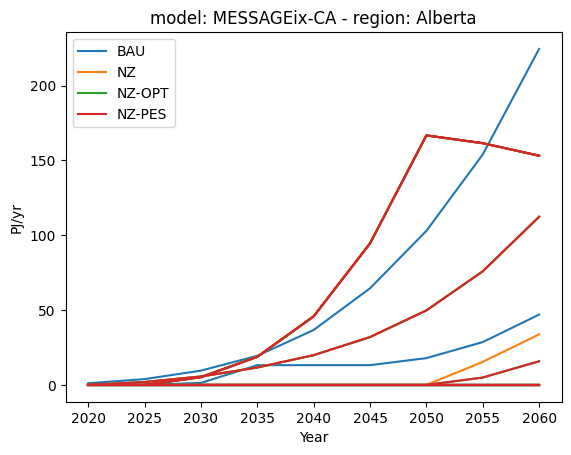

In [29]:
df_pyam.filter(variable = 'Secondary Energy|Hydrogen*',region = 'Alberta').plot(color = 'scenario')

In [ ]:
df_pyam.filter(variable = 'Investment*Hydrogen*Fossil*',region = 'BritishColumbia').plot()

In [33]:
df_pyam = df_pyam.filter(variable = ['Water*',
                                      'Resource|Cumulative*', 'GDP*',
                                      'Population*','Commulative*','*Trade*','Useful Energy|Input*',
                                      'Primary Energy (substitution method)*'],keep = False )

In [119]:
df_pyam = df_pyam.filter(variable = var_lis, keep = False)

In [34]:
from cycler import K
import yaml
import pandas as pd

# Load the YAML file
yaml_file_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/iamc_structure.yaml'
with open(yaml_file_path, 'r') as file:
    vars_agg = yaml.safe_load(file)

# List to keep track of problematic variables
problematic_variables = []

# Loop through each item in the aggregation dictionary
for variable, components in vars_agg.items():
    try:
        # Attempt to aggregate each variable with its components
        df_pyam.aggregate(variable=variable, components=components, append=True)
    except ValueError as e:
        # Print the variable causing the issue and the associated error
        problematic_variables.append(variable)
        print(f"Error aggregating {variable}: {e}")
        

[WARNING] 00:19:07 - pyam.utils: Formatted data is empty.
[WARNING] 00:19:07 - pyam.utils: Formatted data is empty.
[WARNING] 00:19:07 - pyam.utils: Formatted data is empty.
[WARNING] 00:19:08 - pyam.utils: Formatted data is empty.
[WARNING] 00:19:09 - pyam.utils: Formatted data is empty.
[WARNING] 00:19:09 - pyam.utils: Formatted data is empty.


In [114]:
problematic_variables

['Carbon Sequestration|CCS|Industrial Processes']

In [35]:
df_pyam_baseline = df_pyam.filter(scenario='BAU')
df_pyam_netzero = df_pyam.filter(scenario = 'NZ')
df_pyam_netzero_opt = df_pyam.filter(scenario = 'NZ-OPT')
df_pyam_netzero_pes = df_pyam.filter(scenario = 'NZ-PES')

In [36]:
df =df_pyam_baseline.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_baseline.csv')

In [37]:
df =df_pyam_netzero.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_netzero.csv')

In [38]:
df =df_pyam_netzero_opt.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_netzero_opt.csv')

In [39]:
df =df_pyam_netzero_pes.as_pandas()
df['value'] = df['value'].astype(float)
df['model'] = 'MESSAGEix-Canada'
df.rename(columns={'year':'time'}, inplace=True)
df.to_csv('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_pyam_netzero_pes.csv')

In [ ]:
# import pandas as pd
# import yaml

# # Load the CSV file
# file_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/default_aggregates.csv'
# df = pd.read_csv(file_path)

# # Replace 'XXX' with 'CO2' in both 'IAMC Parent' and 'IAMC Child' columns
# df['IAMC Parent'] = df['IAMC Parent'].str.replace('XXX', 'CO2')
# df['IAMC Child'] = df['IAMC Child'].str.replace('XXX', 'CO2')

# # Group the IAMC Child entries by IAMC Parent
# iamc_dict = df.groupby('IAMC Parent')['IAMC Child'].apply(list).to_dict()

# # Convert the dictionary to YAML format
# yaml_output = yaml.dump(iamc_dict, sort_keys=False)

# # Save the YAML output to a file
# output_file_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/iamc_structure.yaml'
# with open(output_file_path, 'w') as file:
#     file.write(yaml_output)

# print(f"YAML file saved to: {output_file_path}")


YAML file saved to: /Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/iamc_structure.yaml


In [125]:
import yaml
import random

def read_yaml(file_path):
    with open(file_path, 'r') as file:
        data = yaml.safe_load(file)
    return data

def write_yaml(file_path, data):
    with open(file_path, 'w') as file:
        yaml.dump(data, file, default_flow_style=False)

def random_color():
    return "#{:06x}".format(random.randint(0, 0xFFFFFF))

def process_yaml(data):
    new_data = {}
    for category, items in data.items():
        group_color = random_color()
        for item in items:
            item_name = item
            new_data[item_name] = {
                "color": random_color(),
                "group": category,
                "group_color": group_color,
                "name": item_name
            }
    return new_data

def main():
    input_file = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/iamc_structure.yaml'  # Replace with your input YAML file path
    output_file = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/output_mapping_idea.yaml'  # Output file path
    data = read_yaml(input_file)
    processed_data = process_yaml(data)
    write_yaml(output_file, processed_data)

if __name__ == "__main__":
    main()

[WARNING] 00:38:01 - pyam.core: Filtered IamDataFrame is empty!


<Axes: xlabel='Year', ylabel='Value'>

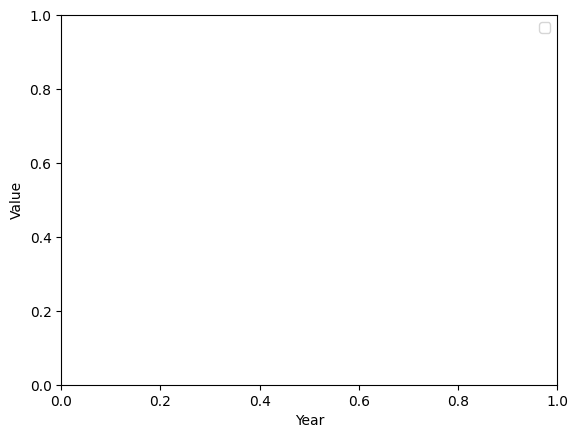

In [40]:
df_pyam.filter(variable = 'Capital Cost*Hydrogen', region = 'Alberta').plot()

<Axes: title={'center': 'model: MESSAGEix-CA - variable: Capital Cost|Hydrogen|Gas|w/ CCS'}, xlabel='Year', ylabel='US$2010/kW'>

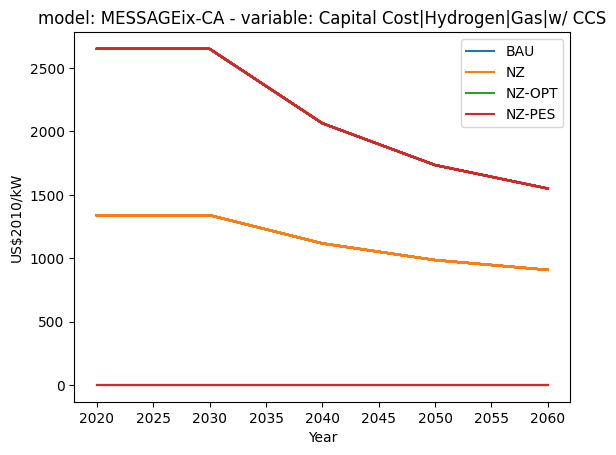

In [46]:
df_pyam.filter(variable = 'Capital Cost|Hydrogen|Gas|w/ CCS').plot(color = 'scenario')